#### Time Series – Daily Demand Forecasting
Here I'll turn sessions into a daily total demand series, study its trend and weekly pattern, and forecast the next 30 days with simple models.

#### Step-0: Setup

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

#### Step-1: Load and build the daily series

In [2]:
# Loading cleaned data
df= pd.read_csv("../data/cleaned/charging_clean.csv", parse_dates=['StartDatetime'])
df.shape

(72088, 9)

In [3]:
# Total demand per day (resample('D') groups rows by calendar day)
daily= df.set_index('StartDatetime')['Demand'].resample('D').sum()
daily.head()

StartDatetime
2021-09-30     579.19
2021-10-01    2467.51
2021-10-02    2066.74
2021-10-03    1887.15
2021-10-04    1768.66
Freq: D, Name: Demand, dtype: float64

In [4]:
# First day (30 Sep 2021) has only a few evening sessions, so it is dropped as a partial day
daily= daily.iloc[1:]
len(daily), daily.index.min(), daily.index.max(), (daily==0).sum()

(365,
 Timestamp('2021-10-01 00:00:00'),
 Timestamp('2022-09-30 00:00:00'),
 np.int64(0))

In [5]:
# Basic summary of daily demand
daily.describe().round(1)

count     365.0
mean     3468.5
std       864.5
min       719.6
25%      2785.8
50%      3531.3
75%      4060.9
max      5879.8
Name: Demand, dtype: float64

#### Step-2: Trend over time

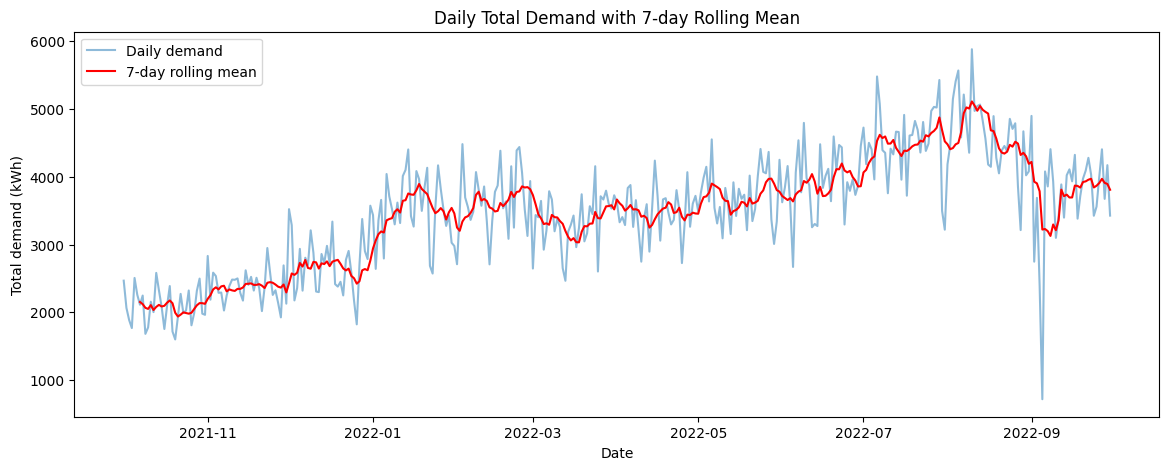

In [6]:
# Daily demand with a 7 day rolling mean (rolling mean smooths daily ups and downs to show the trend)
rolling_7= daily.rolling(7).mean()
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.5, label='Daily demand')
plt.plot(rolling_7.index, rolling_7.values, color='red', label='7-day rolling mean')
plt.title('Daily Total Demand with 7-day Rolling Mean')
plt.xlabel('Date')
plt.ylabel('Total demand (kWh)')
plt.legend()
plt.show()

#### Step-3: Periods of increasing / decreasing demand

In [7]:
# Average daily demand per month and % change from previous month
monthly_avg= daily.groupby(daily.index.to_period('M')).mean()
monthly_change= monthly_avg.pct_change()*100
pd.DataFrame({'AvgDailyDemand': monthly_avg.round(0), 'Change%': monthly_change.round(1)})

,AvgDailyDemand,Change%
StartDatetime,,
2021-10,2084.0,NaN
2021-11,2382.0,14.3
2021-12,2727.0,14.5
2022-01,3520.0,29.1
2022-02,3665.0,4.1
2022-03,3339.0,-8.9
2022-04,3472.0,4.0
2022-05,3716.0,7.0
2022-06,3914.0,5.3


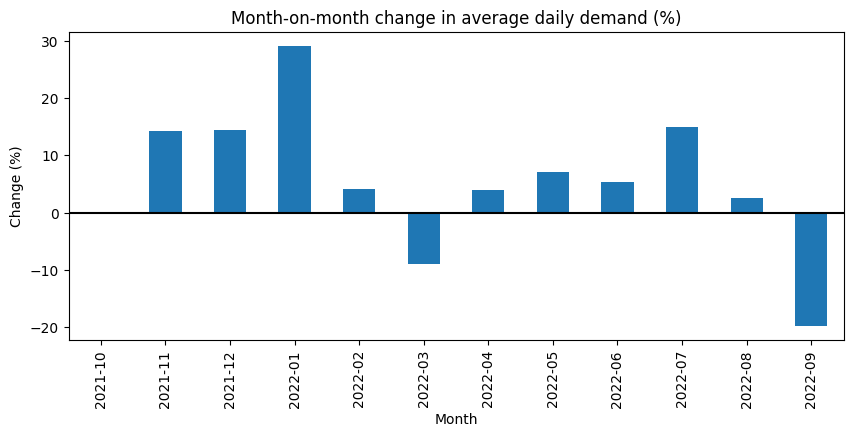

In [8]:
# Plotting month-wise % change
monthly_change.plot(kind='bar', figsize=(10, 4))
plt.axhline(0, color='black')
plt.title('Month-on-month change in average daily demand (%)')
plt.xlabel('Month')
plt.ylabel('Change (%)')
plt.show()

#### Step-4: Weekly pattern

In [10]:
# Average daily demand per weekday (to check if demand repeats every week)
weekday_avg= daily.groupby(daily.index.day_name()).mean().sort_values(ascending=False)
weekday_avg.round(0)

StartDatetime
Thursday     3724.0
Wednesday    3659.0
Friday       3580.0
Tuesday      3491.0
Monday       3433.0
Saturday     3320.0
Sunday       3069.0
Name: Demand, dtype: float64

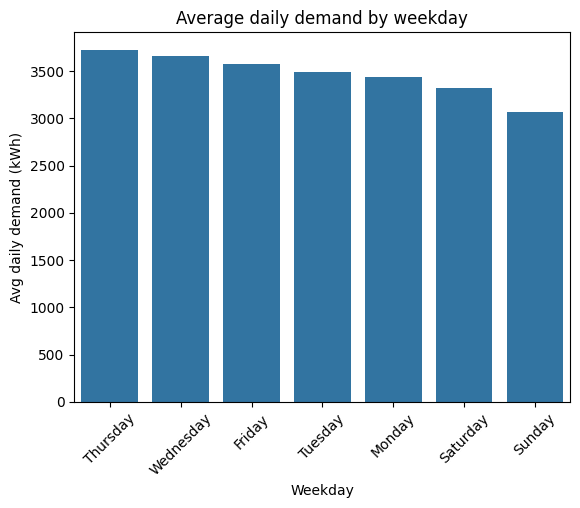

In [11]:
# Plotting weekday averages
sns.barplot(x=weekday_avg.index, y=weekday_avg.values)
plt.title('Average daily demand by weekday')
plt.xlabel('Weekday')
plt.ylabel('Avg daily demand (kWh)')
plt.xticks(rotation=45)
plt.show()

#### Step-5: Unusual days (noise / anomalies)

In [12]:
# Lowest and highest demand days
daily.nsmallest(3).round(1), daily.nlargest(3).round(1)

(StartDatetime
 2022-09-05     719.6
 2021-10-20    1600.8
 2021-10-09    1683.3
 Name: Demand, dtype: float64,
 StartDatetime
 2022-08-10    5879.8
 2022-08-05    5566.0
 2022-07-06    5478.0
 Name: Demand, dtype: float64)

#### Step-6: Decomposition – trend, seasonality and noise
Decomposition splits the series into trend (long-term direction) + seasonality (repeating weekly pattern, period=7) + residual (leftover noise).

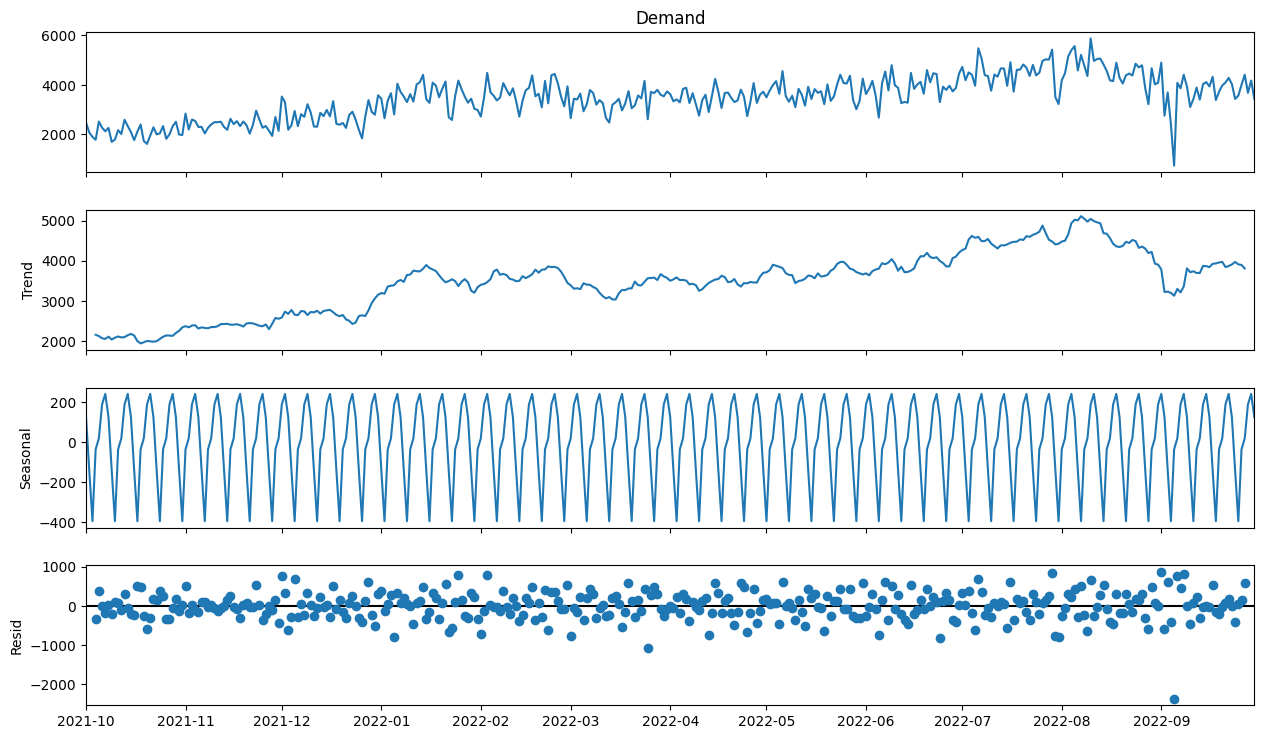

In [13]:
# Additive decomposition with weekly period
decomp= seasonal_decompose(daily, model='additive', period=7)
fig= decomp.plot()
fig.set_size_inches(14, 8)
plt.show()

#### Step-7: Stationarity check (ADF test)
Stationary = mean and variance stay the same over time. ADF test: p-value < 0.05 means stationary.

In [14]:
# ADF test on original daily series
result= adfuller(daily)
print('ADF statistic:', round(result[0], 2))
print('p-value:', round(result[1], 3))

ADF statistic: -1.86
p-value: 0.352


C:\Users\VISHNU KASHYAP\AppData\Local\Temp\ipykernel_20312\625785579.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result= adfuller(daily)


In [15]:
# ADF test after differencing (diff = today minus yesterday, removes the trend)
result_diff= adfuller(daily.diff().dropna())
print('ADF statistic:', round(result_diff[0], 2))
print('p-value:', round(result_diff[1], 3))

ADF statistic: -8.08
p-value: 0.0


C:\Users\VISHNU KASHYAP\AppData\Local\Temp\ipykernel_20312\3920858018.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff= adfuller(daily.diff().dropna())


#### Step-8: Train-test split

In [16]:
# Last 30 days (September 2022) kept as test; no shuffling, because order matters in time series
train= daily.iloc[:-30]
test= daily.iloc[-30:]
len(train), len(test), train.index[-1], test.index[0]

(335, 30, Timestamp('2022-08-31 00:00:00'), Timestamp('2022-09-01 00:00:00'))

#### Step-9: Forecasting models

In [17]:
# Function to print and store MAE and RMSE for each model's 30-day forecast
results= []
def evaluate(name, pred):
    mae= mean_absolute_error(test, pred)
    rmse= np.sqrt(mean_squared_error(test, pred))
    results.append([name, round(mae, 1), round(rmse, 1)])
    print(name, '| MAE:', round(mae, 1), '| RMSE:', round(rmse, 1))

In [18]:
# Naive baseline: every future day = last known day's demand
naive_pred= pd.Series(train.iloc[-1], index=test.index)
evaluate('Naive', naive_pred)

Naive | MAE: 514.5 | RMSE: 835.7


In [19]:
# Moving Average: every future day = average of the last 7 days
ma_pred= pd.Series(train.iloc[-7:].mean(), index=test.index)
evaluate('Moving Average (7)', ma_pred)

Moving Average (7) | MAE: 580.2 | RMSE: 891.9


In [20]:
# Simple Exponential Smoothing: weighted average where recent days get more weight (alpha = weight)
ses= SimpleExpSmoothing(train, initialization_method='estimated').fit()
ses_pred= ses.forecast(30)
print('alpha:', round(ses.params['smoothing_level'], 3))
evaluate('Simple Exp Smoothing', ses_pred)

alpha: 0.169
Simple Exp Smoothing | MAE: 617.4 | RMSE: 923.7


In [21]:
# Holt's method: exponential smoothing + trend
holt= ExponentialSmoothing(train, trend='add', initialization_method='estimated').fit()
holt_pred= holt.forecast(30)
evaluate('Holt (trend)', holt_pred)

Holt (trend) | MAE: 742.6 | RMSE: 1012.9


In [22]:
# Holt-Winters: exponential smoothing + trend + weekly seasonality
hw= ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=7, initialization_method='estimated').fit()
hw_pred= hw.forecast(30)
evaluate('Holt-Winters (trend + seasonal)', hw_pred)

Holt-Winters (trend + seasonal) | MAE: 696.2 | RMSE: 951.9


In [23]:
# Holt-Winters with weekly seasonality only (no trend)
hw_s= ExponentialSmoothing(train, seasonal='add', seasonal_periods=7, initialization_method='estimated').fit()
hw_s_pred= hw_s.forecast(30)
evaluate('Holt-Winters (seasonal only)', hw_s_pred)

Holt-Winters (seasonal only) | MAE: 576.1 | RMSE: 866.0


#### Step-10: Model comparison

In [24]:
# All models side by side (lower MAE / RMSE = better)
results_df= pd.DataFrame(results, columns=['Model', 'MAE', 'RMSE']).sort_values('MAE')
results_df

,Model,MAE,RMSE
0,Naive,514.5,835.7
5,Holt-Winters (seasonal only),576.1,866.0
1,Moving Average (7),580.2,891.9
2,Simple Exp Smoothing,617.4,923.7
4,Holt-Winters (trend + seasonal),696.2,951.9
3,Holt (trend),742.6,1012.9


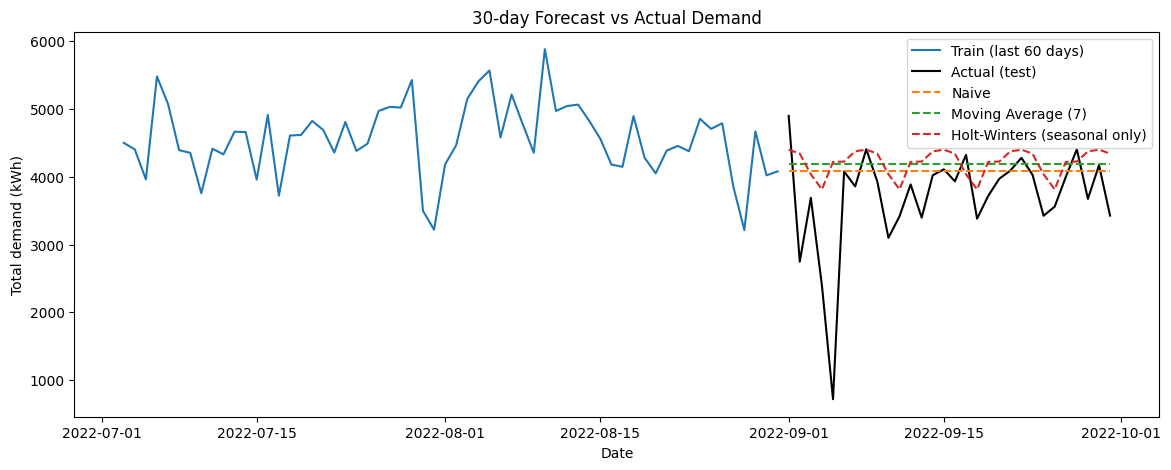

In [25]:
# Actual September demand vs forecasts of the main models
plt.figure(figsize=(14, 5))
plt.plot(train.index[-60:], train.values[-60:], label='Train (last 60 days)')
plt.plot(test.index, test.values, color='black', label='Actual (test)')
plt.plot(test.index, naive_pred.values, linestyle='--', label='Naive')
plt.plot(test.index, ma_pred.values, linestyle='--', label='Moving Average (7)')
plt.plot(test.index, hw_s_pred.values, linestyle='--', label='Holt-Winters (seasonal only)')
plt.title('30-day Forecast vs Actual Demand')
plt.xlabel('Date')
plt.ylabel('Total demand (kWh)')
plt.legend()
plt.show()

#### Observations:
1. Demand rises over the year in steps, with the biggest jumps in January and July, and drops in March and September.
2. Weekdays are busier than weekends, and Sunday is the lowest day, so there is a weekly pattern (seasonality of 7 days).
3. 5 Sep 2022 is an unusual low day (anomaly) and falls inside the test period.
4. The original series is not stationary; after differencing it becomes stationary.
5. Simple models (Naive, Moving Average, Holt-Winters seasonal only) beat the trend models, because demand dropped in September after the summer growth and the trend models kept forecasting growth.
6. Holt-Winters (seasonal only) is close to the best and also captures the weekly pattern.
7. Sessions were converted into a daily total demand series for one full year.
8. Trend, weekly seasonality and noise were checked using a rolling mean, weekday averages and decomposition.
9. ADF test showed the series needs differencing to become stationary.
10. Moving Average and Exponential Smoothing models were compared on the last 30 days using MAE and RMSE.
11. Business use: plan maintenance on Sundays (lowest demand), add capacity ahead of growth periods, and refresh forecasts often because demand can shift suddenly.